# **СУММАТОР В КВАНТОВЫХ СХЕМАХ**

**Теория**

Как и в классических вычислениях, где вы можете комбинировать различные логические элементы (например, И, ИЛИ, исключающее ИЛИ и т. д.) для создания двоичных сумматоров, вы также можете создавать сумматоры с помощью квантовых схем.


In [ ]:
!pip install qiskit pylatexenc qiskit-aer

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 162.6/162.6 kB 6.6 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.4/7.4 MB 54.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 12.4/12.4 MB 54.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.2/2.2 MB 53.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.5/49.5 kB 3.1 MB/s eta 0:00:00
  Created wheel for pylatexenc: filename=pylatexenc-2.10-py3-none-any.whl size=136817 sha256=8139b2fd20dcd993a519e54bbb2f4c351ba28f0c9c702983fc745b68025f3c9a
  Stored in directory: /root/.cache/pip/wheels/06/3e/78/fa1588c1ae991bbfd814af2bcac6cef7a178beee1939180d46
Successfully built pylatexenc


In [ ]:
from qiskit import QuantumCircuit
from qiskit_aer import Aer
from qiskit.visualization import plot_bloch_multivector

*Что такое квантовые схемы?*
Квантовые схемы — это модели квантовых вычислений, в которых вычисление представляет собой последовательность квантовых вентилей. Давайте взглянем на некоторые популярные квантовые вентили.


## X Вентиль

X-вентиль соответствует вращению вокруг оси X сферы Блоха на π радиан. Он ставит |0⟩ в соответствие |1⟩ и |1⟩ в соответствие |0⟩. Это квантовый эквивалент вентиля НЕ для классических компьютеров, который иногда называют инверсией битов.

$X = \begin{pmatrix}
0 & 1 \\
1 & 0 \\
\end{pmatrix}$






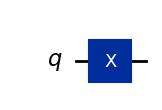

In [ ]:
# Применение X вентиля к кубиту |0>
qc = QuantumCircuit(1)
qc.x(0)
qc.draw("mpl")

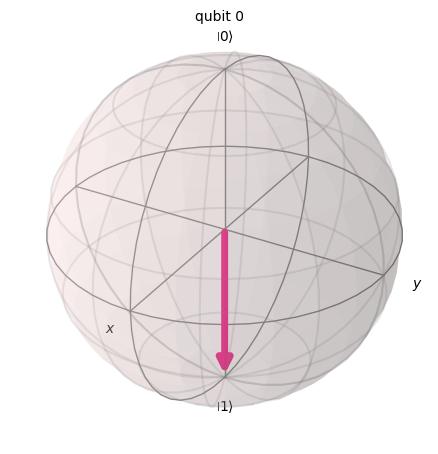

In [ ]:
backend = Aer.get_backend('statevector_simulator')
result = backend.run(qc).result()
statevector = result.get_statevector()

plot_bloch_multivector(statevector)

### H вентиль
Вентиль Адамара представляет собой вращение $\pi$ вокруг оси, которая находится между осями $X$ и $Z$.
Они отображают базовое состояние $|0\rangle$ в $\frac{|0\rangle + |1\rangle}{\sqrt{2}}$, что означает, что измерение будет иметь равные вероятности быть `1` или `0`, создавая "суперпозицию" состояний. Это состояние так же записывается как $|+\rangle$.
Квантовая суперпозиция — это состояние, при котором квантовая система одновременно находится в нескольких возможных состояниях. Это связано с особенностями квантовой механики, где объекты могут существовать в неопределенных состояниях до тех пор, пока не будет выполнено измерение, которое приведет к определенному результату.

$H = \frac{1}{\sqrt{2}}\begin{pmatrix}
1 & 1 \\
1 & -1 \\
\end{pmatrix}$

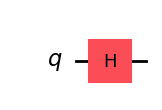

In [ ]:
# Применение вентиля H к кубиту |0>
qc = QuantumCircuit(1)
qc.h(0)
qc.draw("mpl")

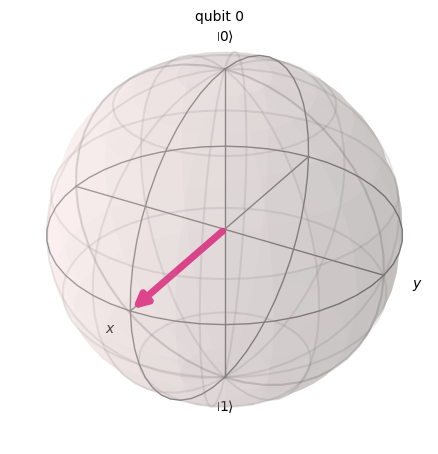

In [ ]:
backend = Aer.get_backend('statevector_simulator')
result = backend.run(qc).result()
statevector = result.get_statevector()

plot_bloch_multivector(statevector)

### Z вентиль
Вентиль Z представляет собой вращение сферы Блоха на $\pi$ радиан. Его иногда называют «вентилем фазового сдвига».

$Z = \begin{pmatrix}
1 & 0 \\
0 & -1 \\
\end{pmatrix}$

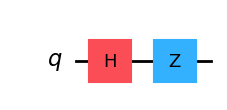

In [ ]:
# Применение Z-вентиля к кубиту |+>
qc = QuantumCircuit(1)
qc.h(0)
qc.z(0)
qc.draw("mpl")

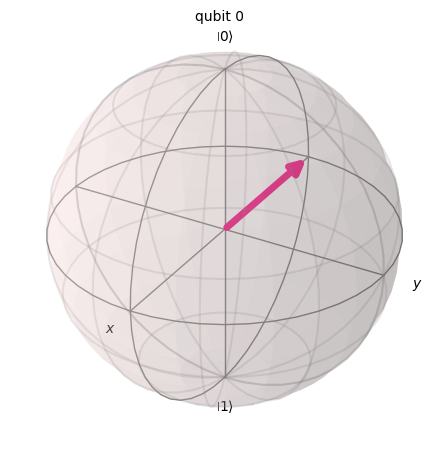

In [ ]:
backend = Aer.get_backend('statevector_simulator')
result = backend.run(qc).result()
statevector = result.get_statevector()

plot_bloch_multivector(statevector)

### CX вентиль (CNOT вентиль)
Управляемый вентиль НЕ (или CNOT или CX) работает с двумя кубитами. Он выполняет операцию НЕ (эквивалент применения X-вентиля) для второго кубита только тогда, когда первый кубит равен $|1\rangle$ а в противном случае оставляет его неизменным. Примечание: Qiskit нумерует биты в строке справа налево.

$CX = \begin{pmatrix}
1 & 0 & 0 & 0\\
0 & 1 & 0 & 0\\
0 & 0 & 0 & 1\\
0 & 0 & 1 & 0\\
\end{pmatrix}$

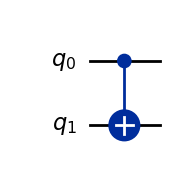

In [ ]:
# Применение Z-вентиля к кубиту |+>
qc = QuantumCircuit(2)
qc.cx(0, 1)
qc.draw("mpl")

### CZ вентиль
Вентиль CZ работает с двумя кубитами, называемыми «бит управления» и «целевой бит». Он меняет знак (эквивалент применения Z-вентиля фазового сдвига) целевого кубита тогда и только тогда, когда управляющий кубит равен $|1\rangle$.

$CZ = \begin{pmatrix}
1 & 0 & 0 & 0\\
0 & 1 & 0 & 0\\
0 & 0 & 1 & 0\\
0 & 0 & 0 & -1\\
\end{pmatrix}$

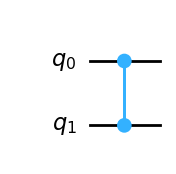

In [ ]:
# Применение CZ-вентиля к кубиту |00>
qc = QuantumCircuit(2)
qc.cz(0, 1)
qc.draw(output='mpl')

Примечание: вентиль CZ также может быть построен из вентиля CX и вентиля H.

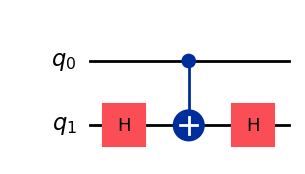

In [ ]:
# Применение вентиля CZ, состоящего из CX-вентиля и H-вентиля
qc = QuantumCircuit(2)

qc.h(1)
qc.cx(0, 1)
qc.h(1)
qc.draw(output='mpl')

### CCX Вентиль
Вентиль CCX также называют вентилем Тоффоли.
Вентиль CCX представляет собой трехбитный вентиль с двумя управляющими битами и одним целевым в качестве входа и выхода. Если первые два бита находятся в состоянии $|1\rangle$, к третьему биту применяется код Паули-X (или НЕ). В противном случае целевой бит остается неизменным. Примечание: Qiskit нумерует биты в строке справа налево.

$CCX = \begin{pmatrix}
1 & 0 & 0 & 0 & 0 & 0 & 0 & 0\\
0 & 1 & 0 & 0 & 0 & 0 & 0 & 0\\
0 & 0 & 1 & 0 & 0 & 0 & 0 & 0\\
0 & 0 & 0 & 1 & 0 & 0 & 0 & 0\\
0 & 0 & 0 & 0 & 1 & 0 & 0 & 0\\
0 & 0 & 0 & 0 & 0 & 1 & 0 & 0\\
0 & 0 & 0 & 0 & 0 & 0 & 0 & 1\\
0 & 0 & 0 & 0 & 0 & 0 & 1 & 0\\
\end{pmatrix}$

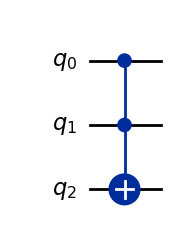

In [ ]:
# Применение CCX-вентиля к кубиту |00>
qc = QuantumCircuit(3)
qc.ccx(0, 1, 2)
qc.draw(output='mpl')

## Создание логических вентилей с помощью квантовых вентилей
Квантовые регистры обозначены как «q», а классические регистры как «c», где кодируются выходные данные измерения.

### НЕ (NOT) вентиль
Как упоминалось ранее, вентиль X можно рассматривать как вентиль НЕ. Таблица истинности для вентиля НЕ выглядит следующим образом:


|input|output|
|--|--|
|0|1|
|1|0|

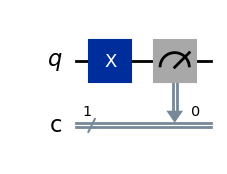

In [ ]:
# Создание квантовой схемы с 1 квантовым регистром и 1 классическим регистром.
qc = QuantumCircuit(1,1)
qc.x(0)
qc.measure(0, 0)    # Сопоставление квантовое измерения с классическими битами
qc.draw(output='mpl')

### И (AND) вентиль
Таблица истинности для вентиля И выглядит следующим образом:

|A (input)|B (input)|output|
|--|--|--|
|0|0|0|
|0|1|0|
|1|0|0|
|1|1|1|

При использовании вентиля CCX результат логического элемента И для двух битов управления будет выведен в целевой бит.

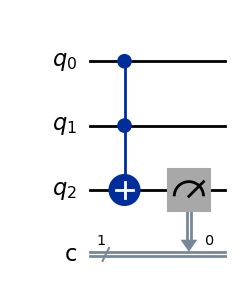

In [ ]:
qc = QuantumCircuit(3,1)
qc.ccx(0, 1, 2)
qc.measure(2, 0)
qc.draw(output='mpl')

### И-НЕ (NAND) вентиль
Логический элемент И-НЕ можно создать, применив логический элемент НЕ после применения логического элемента И.

|A(input)|B(input)|output|
|--|--|--|
|0|0|1|
|0|1|1|
|1|0|1|
|1|1|0|

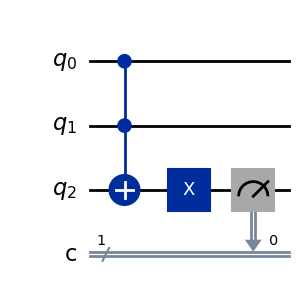

In [ ]:
qc = QuantumCircuit(3, 1)
qc.ccx(0, 1, 2)
qc.x(2)
qc.measure(2, 0)
qc.draw(output='mpl')

### ИЛИ (OR) вентиль

|A(input)|B(input)|output|
|--|--|--|
|0|0|0|
|0|1|1|
|1|0|1|
|1|1|1|

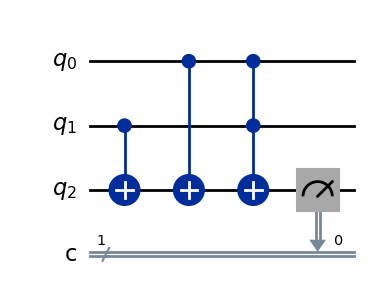

In [ ]:
qc = QuantumCircuit(3, 1)

qc.cx(1, 2)
qc.cx(0, 2)
qc.ccx(0, 1, 2)
qc.measure(2, 0)
qc.draw(output='mpl')

### исключающее ИЛИ (XOR) вентиль
|A(input)|B(input)|output|
|--|--|--|
|0|0|0|
|0|1|1|
|1|0|1|
|1|1|0|

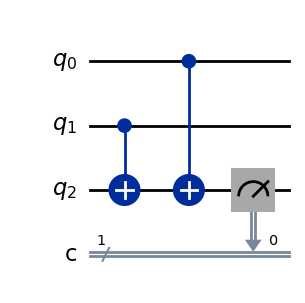

In [ ]:
qc = QuantumCircuit(3, 1)
qc.cx(1, 2)
qc.cx(0, 2)
qc.measure(2, 0)
qc.draw(output='mpl')

### ИЛИ-НЕ (NOR) вентиль

|A(input)|B(input)|output|
|--|--|--|
|0|0|1|
|0|1|0|
|1|0|0|
|1|1|0|

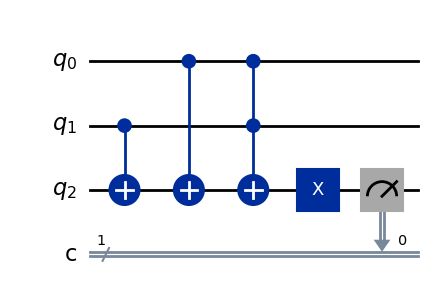

In [ ]:
qc = QuantumCircuit(3, 1)

qc.cx(1, 2)
qc.cx(0, 2)
qc.ccx(0, 1, 2)
qc.x(2)
qc.measure(2, 0)
qc.draw(output='mpl')

# Сумматор

Сумматор — это цифровая логическая схема, выполняющая сложение чисел.

В этом примере мы рассмотрим простейшие сумматоры, а именно полусумматор и полный сумматор.

## Полусумматор
Полусумматор используется для сложения двух младших разрядов двоичной суммы.
Он имеет два одиночных двоичных входа, называемых A и B, и два выхода C (выполнение) и S (суммирование).
Выход C будет использоваться в качестве входа в полный сумматор, который будет объяснен позже, для получения значения в старшем разряде.

Полусумматоры можно описать с помощью таблицы истинности, показанной ниже.

|A (input)|B (input)|S (sum)|C (carry out)|
|-----------|------------|------------|------------|
|0|0|0|0|
|0|1|1|0|
|1|0|1|0|
|1|1|0|1|

Из таблицы истинности вы должны заметить, что выход C является результатом применения логического вентиля И к A и B, а выход S является результатом применения логического вентиля XOR к A и B.
Поскольку мы уже создали вентили И и исключающее ИЛИ, мы можем объединить эти вентили и создать полусумматор следующим образом.

Мы обозначаем наш квантовый регистр как «q», классические регистры как «c», назначаем входы A и B для q[0] и q[1], суммируем выход S и переносим выход C в q[2] и q[3].

{'00': 1000}


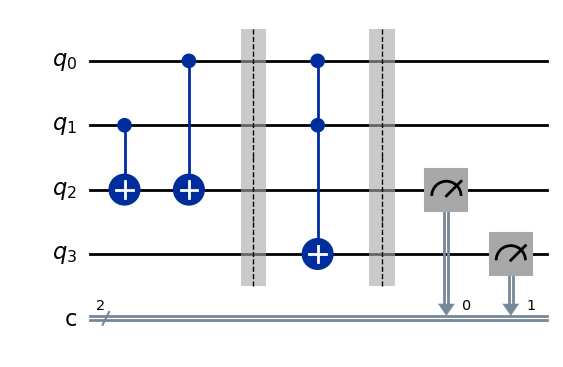

In [ ]:
# Определение регистров и квантовой схемы
qc = QuantumCircuit(4, 2)

# XOR
qc.cx(1, 2)
qc.cx(0, 2)
qc.barrier()

# AND
qc.ccx(0, 1, 3)
qc.barrier()

# расчет S
qc.measure(2, 0)
# расчет C
qc.measure(3, 1)

backend = Aer.get_backend('qasm_simulator')
job = backend.run(qc, shots=1000)
result = job.result()
count =result.get_counts()
print(count)

qc.draw(output='mpl')